## Projet 🚧

Les data scientists qui ont créé la newsletter souhaitent mieux comprendre le comportement des utilisateurs visitant leur site web. Ils aimeraient savoir s’il est possible de construire un modèle qui prédit si un utilisateur donné s’abonnera à la newsletter, en utilisant seulement quelques informations sur l’utilisateur. Ils souhaitent analyser les paramètres du modèle afin de mettre en évidence les caractéristiques importantes pour expliquer le comportement des utilisateurs, et peut-être découvrir un nouveau levier d’action pour améliorer le taux de conversion de la newsletter.

**Plan de l'analyse** :
- **Partie 1** — EDA, préprocessing et modèle de base
- **Partie 2** — Amélioration du F1-score (rééquilibrage, modèles plus complexes, GridSearch)
- **Partie 3** — Précision, recall et choix du seuil de décision
- **Partie 4** — Que reste-t-il sans le nombre de pages vues ?
- **Partie 5** — Prédictions sur `conversion_data_test.csv` et export du fichier de soumission
- **Partie 6** — Recommandations business

Métrique de référence pour comparer les modèles (imposée par l'énoncé du challenge) : **F1-score**, complétée par la précision et le recall.

In [4]:
# Installation des bibliothèques (une seule fois par environnement ; sur Colab, seul imbalanced-learn manque)
%pip install -q pandas numpy matplotlib seaborn plotly scikit-learn imbalanced-learn

In [5]:
#Import des bibliothèques
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)

from imblearn.over_sampling import SMOTE
from IPython.display import display

# Paramètres Jedha (palette de couleurs)
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"

# Dossier des fichiers CSV
DATA_DIR = Path("data")

# Partie 1 — EDA, préprocessing et modèle de base

### Import du fichier

In [6]:
df = pd.read_csv(DATA_DIR / "conversion_data_train.csv")
print(f"{df.shape[0]} lignes, {df.shape[1]} colonnes")

284580 lignes, 6 colonnes


284 580 lignes pour seulement 6 colonnes : le dataset comporte de nombreuses lignes mais peu de colonnes, soit peu de variables (5 features + 1 cible `converted`).

### Découverte des infos

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284580 entries, 0 to 284579
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   country              284580 non-null  object
 1   age                  284580 non-null  int64 
 2   new_user             284580 non-null  int64 
 3   source               284580 non-null  object
 4   total_pages_visited  284580 non-null  int64 
 5   converted            284580 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 13.0+ MB


In [8]:
#Vérif des manquants
df.isnull().mean()

,0
country,0.0
age,0.0
new_user,0.0
source,0.0
total_pages_visited,0.0
converted,0.0


Aucune valeur manquante détectée , et les types sont cohérents : `country` et `source` sont bien catégorielles, le reste est numérique.

In [9]:
#Stats de base

df.describe()

,age,new_user,total_pages_visited,converted
count,284580.000000,284580.000000,284580.000000,284580.000000
mean,30.564203,0.685452,4.873252,0.032258
std,8.266789,0.464336,3.341995,0.176685
min,17.000000,0.000000,1.000000,0.000000
25%,24.000000,0.000000,2.000000,0.000000
50%,30.000000,1.000000,4.000000,0.000000
75%,36.000000,1.000000,7.000000,0.000000
max,123.000000,1.000000,29.000000,1.000000


Trois points à retenir :
- **Le taux de conversion moyen sur l'intégralité des données est de 3.2 %** (`converted` moyenne = 0.032) → la cible est fortement déséquilibrée.
- **68.5 % des visiteurs sont des `new_user`** → il y a donc une majorité de primo-visiteurs.
- **L'âge maximum est de 123 ans**, ce qui est peu probable → valeur aberrante à traiter.

Avec 3,2 % d'abonnés, ce déséquilibre va guider toute la suite : un modèle qui répondrait « personne ne s'abonne » aurait raison 97 fois sur 100, tout en étant inutile. C'est pour ça qu'on regarde le F1-score, la précision et le recall plutôt que l'accuracy.

In [10]:
#Vue des données

df.head()

,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0


In [11]:
#Vérif variable impactant la cible

correlations = df.corr(numeric_only=True)["converted"].sort_values(ascending=False)
display(correlations)

,converted
converted,1.000000
total_pages_visited,0.529192
age,-0.088265
new_user,-0.152115


`total_pages_visited` est corrélée à 0.53 avec la cible : c'est la variable la plus liée à la conversion, et de loin.

À l'inverse, `age` (-0.09) et `new_user` (-0.15) sont légèrement corrélées négativement : les utilisateurs plus âgés et les nouveaux visiteurs convertissent un peu moins.

Ces corrélations ne portent que sur les variables numériques : `country` et `source` sont regardées séparément juste en dessous via des taux de conversion groupés.

### Visualisation des informations

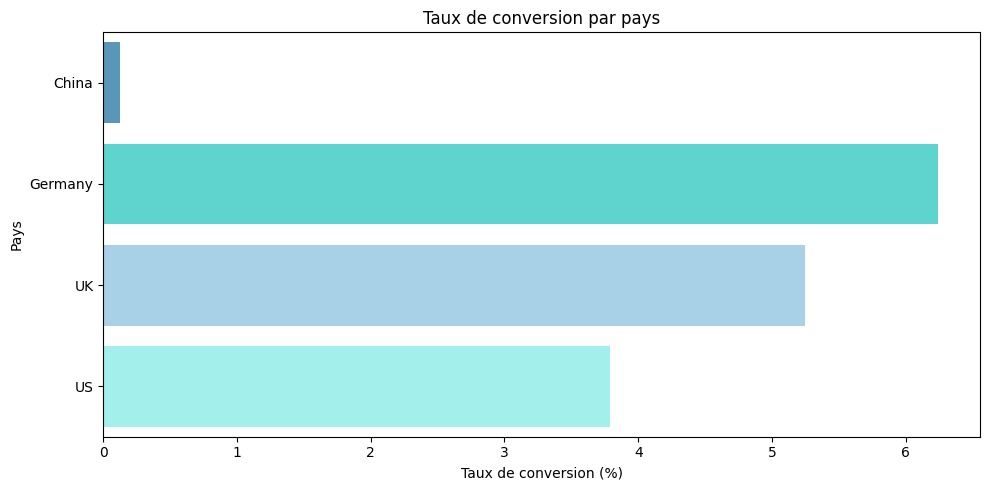

In [12]:
conversion_by_country = df.groupby("country")["converted"].mean().reset_index()
conversion_by_country["converted_percentage"] = conversion_by_country["converted"] * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=conversion_by_country, x="converted_percentage", y="country",
            hue="country",
            palette=pio.templates["jedha"].layout.colorway, ax=ax, legend=False)
ax.set_title("Taux de conversion par pays")
ax.set_xlabel("Taux de conversion (%)")
ax.set_ylabel("Pays")
plt.tight_layout()
plt.show()

In [13]:
# Effectifs par pays : nombre de visiteurs, nombre d'abonnés et taux de conversion
effectifs_pays = df.groupby("country")["converted"].agg(visiteurs="count", abonnes="sum", taux="mean")
effectifs_pays["part_du_trafic_%"] = (effectifs_pays["visiteurs"] / len(df) * 100).round(1)
effectifs_pays["taux_%"] = (effectifs_pays["taux"] * 100).round(2)
effectifs_pays.drop(columns="taux").sort_values("visiteurs", ascending=False)

,visiteurs,abonnes,part_du_trafic_%,taux_%
country,,,,
US,160124,6070,56.3,3.79
China,69122,89,24.3,0.13
UK,43641,2291,15.3,5.25
Germany,11693,730,4.1,6.24


Le taux de conversion varie nettement selon le pays : l'Allemagne (6,2 %) et le Royaume-Uni (5,3 %) convertissent le mieux, les US sont dans la moyenne (3,8 %), et la Chine se détache très nettement vers le bas (0,13 %).

Les effectifs complètent la lecture :
- les **US** représentent 56 % du trafic et apportent les deux tiers des abonnés (6 070 sur 9 180) ;
- l'**Allemagne** convertit le mieux, mais ne pèse que 4 % du trafic ;
- la **Chine** représente un quart du trafic (69 122 visiteurs) pour seulement 89 abonnés. C'est l'écart le plus important du jeu de données.

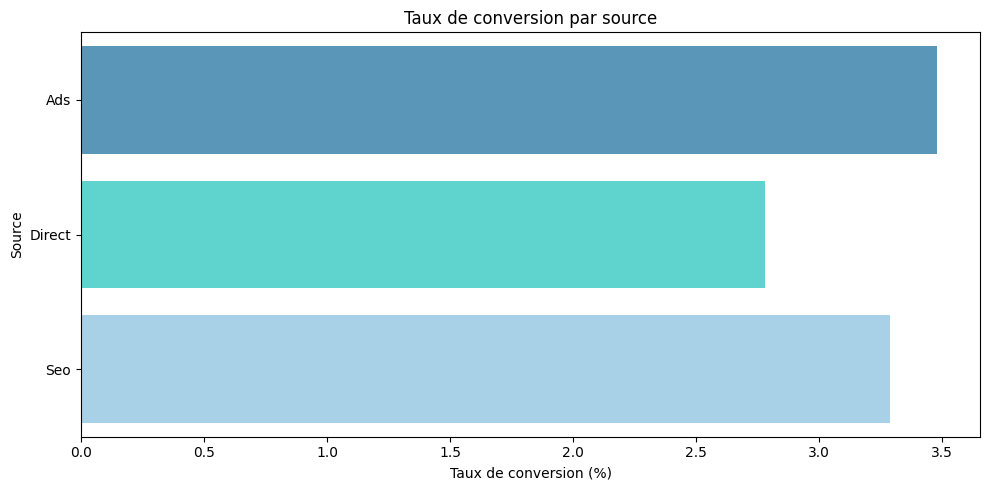

In [14]:
# Taux de conversion par source

conversion_by_source = df.groupby("source")["converted"].mean().reset_index()
conversion_by_source["converted_percentage"] = conversion_by_source["converted"] * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=conversion_by_source, x="converted_percentage", y="source",
            hue="source",
            palette=pio.templates["jedha"].layout.colorway, ax=ax, legend=False)
ax.set_title("Taux de conversion par source")
ax.set_xlabel("Taux de conversion (%)")
ax.set_ylabel("Source")
plt.tight_layout()
plt.show()

In [15]:
# Effectifs par source
effectifs_source = df.groupby("source")["converted"].agg(visiteurs="count", abonnes="sum", taux="mean")
effectifs_source["taux_%"] = (effectifs_source["taux"] * 100).round(2)
display(effectifs_source.drop(columns="taux"))

# La source a-t-elle un effet indirect ? On regarde si certaines sources amènent des visiteurs qui lisent plus
print("Nombre moyen de pages vues par source :")
print(df.groupby("source")["total_pages_visited"].mean().round(2))

,visiteurs,abonnes,taux_%
source,,,
Ads,80027,2785,3.48
Direct,65076,1810,2.78
Seo,139477,4585,3.29


Nombre moyen de pages vues par source :
source
Ads       4.90
Direct    4.82
Seo       4.88
Name: total_pages_visited, dtype: float64


Les trois sources ont de gros volumes (de 65 000 à 139 000 visiteurs), et leurs taux restent proches : de 2,8 % (Direct) à 3,5 % (Ads). L'écart n'est pas nul, mais il reste inférieur à un point.

Pas d'effet indirect visible non plus : les trois sources amènent des visiteurs qui lisent autant (entre 4,8 et 4,9 pages en moyenne). La source aura donc probablement peu de poids dans le modèle.

In [16]:
# Taux de conversion des nouveaux visiteurs (1) et de ceux qui reviennent (0)
effectifs_new = df.groupby("new_user")["converted"].agg(visiteurs="count", abonnes="sum", taux="mean")
effectifs_new["taux_%"] = (effectifs_new["taux"] * 100).round(2)
effectifs_new.drop(columns="taux")

,visiteurs,abonnes,taux_%
new_user,,,
0,89514,6439,7.19
1,195066,2741,1.41


Écart très net : les visiteurs qui reviennent (`new_user` = 0) s'abonnent à 7,2 %, contre 1,4 % pour les nouveaux, soit cinq fois plus. Les nouveaux visiteurs représentent pourtant 68,5 % du trafic.

### Filtre âge pour cas extrême

In [17]:
print(f"Avant filtre outlier âge : {df.shape[0]} lignes")
df = df[df['age'] < 100].copy()
print(f"Après filtre outlier âge : {df.shape[0]} lignes")

Avant filtre outlier âge : 284580 lignes
Après filtre outlier âge : 284578 lignes


Seulement 2 lignes supprimées (284 580 → 284 578) : l'anomalie d'âge à 123 ans repérée dans le `.describe()` était un cas isolé, pas un problème de qualité de données généralisé.

Le filtre à 100 ans est volontairement large, pour ne pas toucher aux valeurs réalistes.

### Préprocessing pour modèle avec 1 variable ("total_pages_visited")

In [18]:
target = "converted"

# 1.Train/Test Split
#stratify pour prendre en compte le déséquilibre
train_df, test_df = train_test_split(df, test_size=0.1, random_state=0, stratify=df[target])

# 2. Encodage Y
enc = LabelEncoder()
Y_train_encoded = enc.fit_transform(train_df[target])
Y_test_encoded  = enc.transform(test_df[target])

# 3. Préprocessing pour modèle avec 1 variable ("total_pages_visited")
numeric_features_1var = ["total_pages_visited"]

X_train_1var_df = train_df[numeric_features_1var]
X_test_1var_df  = test_df[numeric_features_1var]

numeric_transformer_1var = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")), #sécurité au cas où
    ("scaler",  StandardScaler())
])

preprocessor_1var = ColumnTransformer(transformers=[
    ("num", numeric_transformer_1var, numeric_features_1var)
])

X_train_1var_processed = preprocessor_1var.fit_transform(X_train_1var_df)
X_test_1var_processed  = preprocessor_1var.transform(X_test_1var_df)

col_names_1var = numeric_features_1var

In [19]:
# Petite fonction pour afficher F1, précision et recall de chaque modèle, et les garder pour la comparaison
resultats = []

def afficher_scores(nom, y_vrai, y_predit):
    f1 = f1_score(y_vrai, y_predit)
    precision = precision_score(y_vrai, y_predit)   # quand le modèle annonce un abonné, a-t-il raison ?
    recall = recall_score(y_vrai, y_predit)         # parmi les vrais abonnés, combien sont repérés ?
    print(f"{nom} — F1 : {f1:.3f} | précision : {precision:.3f} | recall : {recall:.3f}")
    resultats.append({"Modèle": nom, "F1": round(f1, 3), "Précision": round(precision, 3), "Recall": round(recall, 3)})

### Modèle Régression Logistique 1 variable ("total_pages_visited")

In [20]:
# Régression Logistique 1 variable
model_logreg_1var = LogisticRegression(random_state=0, class_weight="balanced")
model_logreg_1var.fit(X_train_1var_processed, Y_train_encoded)

# Prédictions sur l'ensemble de train
Y_pred_train_logreg_1var = model_logreg_1var.predict(X_train_1var_processed)

# Prédictions sur l'ensemble de test
Y_pred_test_logreg_1var = model_logreg_1var.predict(X_test_1var_processed)

# F1-score
f1_logreg_1var = round(f1_score(Y_test_encoded, Y_pred_test_logreg_1var), 3)
print("Logistic Regression (1 var) - F1 train: ", round(f1_score(Y_train_encoded, Y_pred_train_logreg_1var), 3))
print("Logistic Regression (1 var) - F1 test: ", f1_logreg_1var)
afficher_scores("Régression logistique (1 variable)", Y_test_encoded, Y_pred_test_logreg_1var)

Logistic Regression (1 var) - F1 train:  0.493
Logistic Regression (1 var) - F1 test:  0.482
Régression logistique (1 variable) — F1 : 0.482 | précision : 0.331 | recall : 0.886


**F1 test = 0.482** pour cette première baseline (régression logistique, 1 seule variable, `class_weight="balanced"`).

La précision et le recall expliquent ce score :
- le modèle repère **89 %** des abonnés (recall 0.886) ;
- mais quand il annonce un abonné, il n'a raison qu'**une fois sur trois** (précision 0.331).

C'est l'effet de `class_weight="balanced"` : en donnant plus de poids aux abonnés, le modèle préfère les fausses alertes aux oublis.

Objectif Partie 2 : trouver mieux.

#### Matrice de Confusion pour Régression Logistique 1 variable ("total_pages_visited")

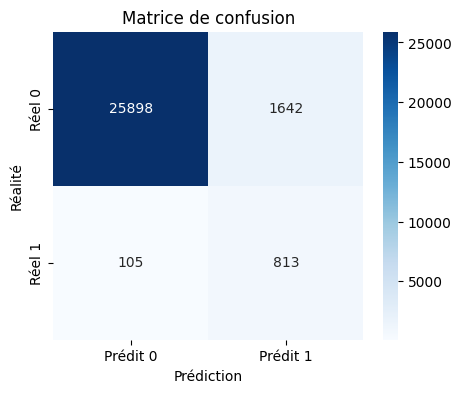

In [21]:
# Matrice de confusion
cm = confusion_matrix(Y_test_encoded, Y_pred_test_logreg_1var)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit 0","Prédit 1"],
            yticklabels=["Réel 0","Réel 1"])
ax.set_ylabel("Réalité"); ax.set_xlabel("Prédiction")
plt.title("Matrice de confusion"); plt.show()

La matrice de confusion confirme : peu d'abonnés manqués, mais beaucoup de fausses alertes.

# Partie 2 — Amélioration du F1 score

### Modèle Régression Logistique 1 variable ("total_pages_visited") + SMOTE pour gérer le déséquilibre

In [22]:
smote = SMOTE(random_state=0)

X_train_res_1var, Y_train_res_1var = smote.fit_resample(X_train_1var_processed, Y_train_encoded)
print("Avant SMOTE :", pd.Series(Y_train_encoded).value_counts().to_dict())
print("Après SMOTE :", pd.Series(Y_train_res_1var).value_counts().to_dict())

Avant SMOTE : {0: 247860, 1: 8260}
Après SMOTE : {0: 247860, 1: 247860}


Le déséquilibre confirmé par les chiffres est très important : **247 860 non-convertis pour seulement 8 260 convertis** dans le train set, soit un ratio d'environ 30 contre 1.

SMOTE rééquilibre artificiellement les deux classes en générant des exemples synthétiques de la classe minoritaire (converted).

In [23]:
model_logreg_smote_1var = LogisticRegression(random_state=0) # Entraînement sur les données rééquilibrées par SMOTE (pas de class_weight nécessaire)
model_logreg_smote_1var.fit(X_train_res_1var, Y_train_res_1var)
print(model_logreg_smote_1var)

LogisticRegression(random_state=0)


In [24]:
# Prédictions sur l'ensemble de train
Y_pred_res_train_logreg_1var = model_logreg_smote_1var.predict(X_train_res_1var)

# Prédictions sur l'ensemble de test
Y_pred_res_test_logreg_1var = model_logreg_smote_1var.predict(X_test_1var_processed)

# F1-score
f1_logreg_smote_1var = round(f1_score(Y_test_encoded, Y_pred_res_test_logreg_1var), 3)
print("Logistic Regression + SMOTE (1 var) - F1 train: ", round(f1_score(Y_train_res_1var, Y_pred_res_train_logreg_1var), 3))
print("Logistic Regression + SMOTE (1 var) - F1 test: ", f1_logreg_smote_1var)
afficher_scores("Régression logistique + SMOTE (1 variable)", Y_test_encoded, Y_pred_res_test_logreg_1var)

Logistic Regression + SMOTE (1 var) - F1 train:  0.919
Logistic Regression + SMOTE (1 var) - F1 test:  0.482
Régression logistique + SMOTE (1 variable) — F1 : 0.482 | précision : 0.331 | recall : 0.886


Avec l'ajout de SMOTE, le F1 sur le train set explose (0.493 → 0.919), mais le **F1 sur le test set reste strictement identique (0.482)**.

Ce qui signifie que SMOTE fait mieux apprendre le modèle sur des données synthétiques, mais n'apporte **aucun gain de généralisation**.

Attention donc à ne pas focaliser uniquement sur le F1 du train set.

#### Matrice de Confusion pour Régression Logistique 1 variable ("total_pages_visited") + SMOTE

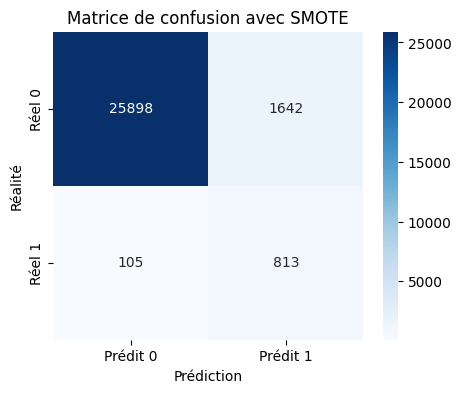

In [25]:
# Matrice de confusion
cm = confusion_matrix(Y_test_encoded, Y_pred_res_test_logreg_1var)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit 0","Prédit 1"],
            yticklabels=["Réel 0","Réel 1"])
ax.set_ylabel("Réalité"); ax.set_xlabel("Prédiction")
plt.title("Matrice de confusion avec SMOTE"); plt.show()

Matrice quasi identique à la version sans SMOTE côté test : cohérent avec le F1 test inchangé.

### Modèle Random Forest 1 variable ("total_pages_visited") + GridSearch pour trouver les meilleurs paramètres

In [26]:
params_rf = {
    "max_depth":         [8, 10, 12],
    "min_samples_leaf":  [1, 2, 5],
    "min_samples_split": [2, 4, 8],
    "n_estimators":      [20, 50, 100],
}

gs_rf_1var = GridSearchCV(RandomForestClassifier(random_state=0), params_rf, cv=3, scoring="f1", n_jobs=-1)
gs_rf_1var.fit(X_train_1var_processed, Y_train_encoded)
print("RF (1 var) — meilleurs params :", gs_rf_1var.best_params_)
f1_rf_1var = round(f1_score(Y_test_encoded, gs_rf_1var.predict(X_test_1var_processed)), 3)
print("RF (1 var) — F1 test          :", f1_rf_1var)
afficher_scores("Random Forest (1 variable)", Y_test_encoded, gs_rf_1var.predict(X_test_1var_processed))

# Importance des caractéristiques (utilisation de col_names_1var)
feat_imp_1var = pd.DataFrame({
    "feature":    col_names_1var,
    "importance": gs_rf_1var.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False)
print("Importance des caractéristiques (1 var):\n", feat_imp_1var)

RF (1 var) — meilleurs params : {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 20}
RF (1 var) — F1 test          : 0.696
Random Forest (1 variable) — F1 : 0.696 | précision : 0.812 | recall : 0.609
Importance des caractéristiques (1 var):
                feature  importance
0  total_pages_visited         1.0


Nette progression avec le Random Forest + GridSearch : **F1 test = 0.696**, contre 0.482 pour la régression logistique.

Le détail montre que le gain vient de la précision (0.812 contre 0.331) : le Random Forest fait beaucoup moins de fausses alertes. En revanche, il repère moins d'abonnés (recall 0.609 contre 0.886).

L'importance de variable à 1.0 est logique puisque nous n'avons qu'une seule feature en entrée.

#### Matrice de Confusion pour RandomForest 1 variable ("total_pages_visited") + GridSearch

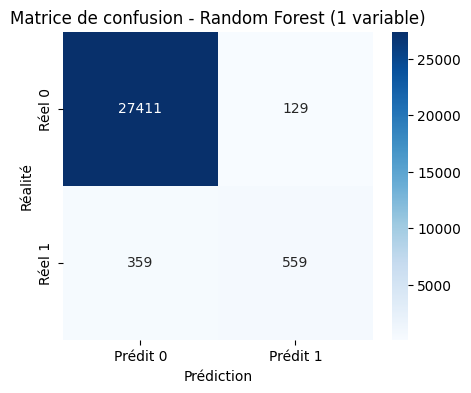

In [27]:
# Matrice de confusion
Y_pred_rf_1var = gs_rf_1var.predict(X_test_1var_processed)
cm = confusion_matrix(Y_test_encoded, Y_pred_rf_1var)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit 0","Prédit 1"],
            yticklabels=["Réel 0","Réel 1"])
ax.set_ylabel("Réalité"); ax.set_xlabel("Prédiction")
plt.title("Matrice de confusion - Random Forest (1 variable)"); plt.show()

Comparée aux matrices de la régression logistique, on voit ici beaucoup moins de faux positifs (129 contre 1 642), mais aussi moins de vrais positifs (559 contre 813). Le gain de précision l'emporte largement sur la perte de recall, d'où le meilleur F1.

### Passage à toutes les variables

#### Preprocessing pour toutes les variables

In [28]:
# Nouveau Train/Test Split avec split similaire mais avec toutes les variables
X_train_allvars_df = train_df.drop(columns=[target])
X_test_allvars_df  = test_df.drop(columns=[target])

# Séparation automatique numérique / catégoriel : évite de lister les colonnes à la main
numeric_features_allvars = X_train_allvars_df.select_dtypes(include=np.number).columns.tolist()
categorical_features_allvars = X_train_allvars_df.select_dtypes(include=["object", "string"]).columns.tolist()

numeric_transformer_allvars = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler())
])

categorical_transformer_allvars = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown='ignore')) # handle_unknown='ignore' : sécurise le futur transform() sur data_test.csv si nouvelle valeur
])

preprocessor_allvars = ColumnTransformer(transformers=[
    ("num", numeric_transformer_allvars,     numeric_features_allvars),
    ("cat", categorical_transformer_allvars, categorical_features_allvars)
])

X_train_allvars_processed = preprocessor_allvars.fit_transform(X_train_allvars_df)
X_test_allvars_processed  = preprocessor_allvars.transform(X_test_allvars_df)

# get_feature_names_out : récupère les noms des colonnes one-hot générées pour lire ensuite par nom
col_names_allvars = numeric_features_allvars + list(preprocessor_allvars.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features_allvars))

### Modèle Régression Logistique (toutes variables)

In [29]:
model_logreg_allvars = LogisticRegression(random_state=0, class_weight="balanced") # Même logique que le modèle 1 variable : class_weight="balanced" pour compenser le déséquilibre
model_logreg_allvars.fit(X_train_allvars_processed, Y_train_encoded)
print(model_logreg_allvars)

LogisticRegression(class_weight='balanced', random_state=0)


In [30]:
# Prédictions sur l'ensemble de train
Y_pred_train_logreg_allvars = model_logreg_allvars.predict(X_train_allvars_processed)

# Prédictions sur l'ensemble de test
Y_pred_test_logreg_allvars = model_logreg_allvars.predict(X_test_allvars_processed)

# F1-score
f1_logreg_allvars = round(f1_score(Y_test_encoded, Y_pred_test_logreg_allvars), 3)
print("Logistic Regression (all vars) - F1 train: ", round(f1_score(Y_train_encoded, Y_pred_train_logreg_allvars), 3))
print("Logistic Regression (all vars) - F1 test: ", f1_logreg_allvars)
afficher_scores("Régression logistique (toutes variables)", Y_test_encoded, Y_pred_test_logreg_allvars)

Logistic Regression (all vars) - F1 train:  0.509
Logistic Regression (all vars) - F1 test:  0.508
Régression logistique (toutes variables) — F1 : 0.508 | précision : 0.349 | recall : 0.936


**F1 test = 0.508**, à peine mieux que la version 1 variable (0.482) et très loin du Random Forest.

À ce stade, on pourrait conclure que la régression logistique est limitée parce qu'elle est linéaire. C'est ce que j'avais écrit dans la première version de ce notebook. La Partie 3 montre que ce n'était pas la bonne explication : le problème vient surtout de son seuil de décision.

### Modèle Random Forest + GridSearch (toutes variables)

In [31]:
params_rf = {
    "max_depth":         [8, 10, 12],
    "min_samples_leaf":  [1, 2, 5],
    "min_samples_split": [2, 4, 8],
    "n_estimators":      [20, 50, 100],
}

gs_rf_allvars = GridSearchCV(RandomForestClassifier(random_state=0), params_rf, cv=3, scoring="f1", n_jobs=-1)
gs_rf_allvars.fit(X_train_allvars_processed, Y_train_encoded)
print("RF (toutes vars) — meilleurs params :", gs_rf_allvars.best_params_)
f1_rf_allvars = round(f1_score(Y_test_encoded, gs_rf_allvars.predict(X_test_allvars_processed)), 3)
print("RF (toutes vars) — F1 test          :", f1_rf_allvars)
afficher_scores("Random Forest (toutes variables)", Y_test_encoded, gs_rf_allvars.predict(X_test_allvars_processed))

feat_imp_allvars = pd.DataFrame({
    "feature":    col_names_allvars,
    "importance": gs_rf_allvars.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False)
print("Importance des caractéristiques (toutes vars):\n", feat_imp_allvars)

RF (toutes vars) — meilleurs params : {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 20}
RF (toutes vars) — F1 test          : 0.755
Random Forest (toutes variables) — F1 : 0.755 | précision : 0.843 | recall : 0.683
Importance des caractéristiques (toutes vars):
                feature  importance
2  total_pages_visited    0.888817
1             new_user    0.040737
0                  age    0.036806
3        country_China    0.021393
6           country_US    0.003838
5           country_UK    0.002959
4      country_Germany    0.001732
8        source_Direct    0.001362
9           source_Seo    0.001230
7           source_Ads    0.001126


Avec toutes les variables, le Random Forest passe à **F1 test = 0.755** (contre 0.696 avec 1 seule variable), avec une précision de 0.843 et un recall de 0.683. Les variables ajoutées apportent un peu de signal complémentaire.

La table d'importance hiérarchise clairement les features :
- `total_pages_visited` : **88.9 %** de l'importance — très majoritaire
- `new_user` : 4.1 %
- `age` : 3.7 %
- `country_China` : 2.1 %, les autres pays entre 0.2 % et 0.4 %
- `source` (Direct/Seo/Ads) : entre 0.11 % et 0.14 % chacune — quasi nulle

#### Importance des Caractéristiques (Random Forest toutes variables)

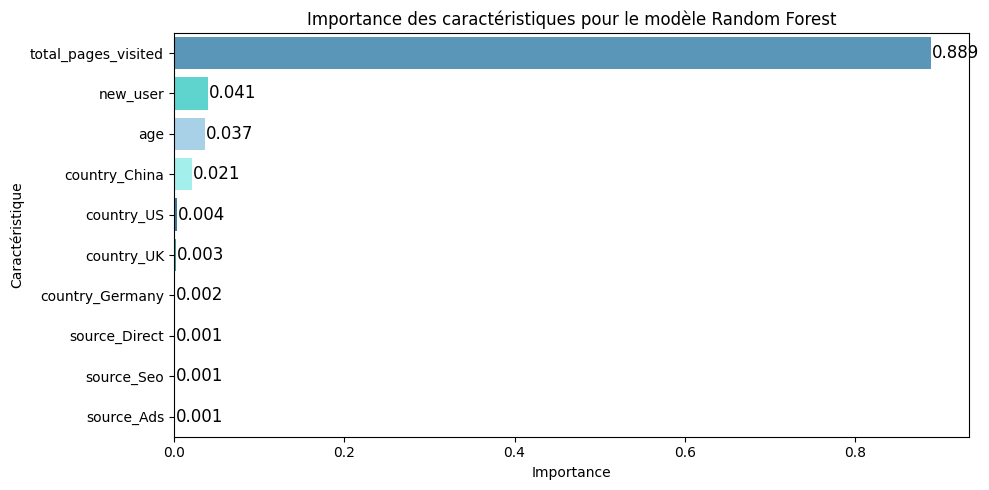

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x="importance", y="feature", data=feat_imp_allvars, palette=pio.templates["jedha"].layout.colorway, hue="feature", legend=False, ax=ax)
plt.title("Importance des caractéristiques pour le modèle Random Forest")
plt.xlabel("Importance")
plt.ylabel("Caractéristique")

# Afficher la valeur à droite de chaque barre
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.001, p.get_y() + p.get_height()/2,
            f'{width:.3f}', va='center', fontsize=12)

plt.tight_layout()
plt.show()

Le graphique rend bien visible l'écart d'échelle entre `total_pages_visited` et le reste : toutes les autres variables réunies ne pèsent qu'environ 11 % de la décision de ce Random Forest.

### Modèle Gradient Boosting (toutes variables)

In [33]:
# Grille volontairement resserrée par rapport au Random Forest
# Limite du nombre de combinaisons car le Gradient Boosting est plus coûteux à entraîner

params_gb = {
    "n_estimators":  [100, 200],
    "max_depth":     [3, 5],
    "learning_rate": [0.05, 0.1], # learning_rate est spécifique à ce modèle : contrôle du poids de correction apporté par chaque nouvel arbre
}

gs_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=0),
    params_gb, cv=5, scoring='f1', n_jobs=-1
)
gs_gb.fit(X_train_allvars_processed, Y_train_encoded)

f1_gb = round(f1_score(Y_test_encoded, gs_gb.predict(X_test_allvars_processed)), 3)
print("GradientBoosting — meilleurs params :", gs_gb.best_params_)
print("GradientBoosting — F1 test          :", f1_gb)
afficher_scores("Gradient Boosting (toutes variables)", Y_test_encoded, gs_gb.predict(X_test_allvars_processed))

GradientBoosting — meilleurs params : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
GradientBoosting — F1 test          : 0.765
Gradient Boosting (toutes variables) — F1 : 0.765 | précision : 0.846 | recall : 0.698


**F1 test = 0.765**, le meilleur score à ce stade, légèrement au-dessus du Random Forest (0.755). La précision (0.846) et le recall (0.698) sont proches de ceux du Random Forest.

Le gain reste modeste (+0.01), signe que l'on approche d'un plafond avec ces 5 variables.

### Comparaison des scores F1

In [34]:
comparaison = pd.DataFrame(resultats).sort_values(by="F1", ascending=False)
display(comparaison)

,Modèle,F1,Précision,Recall
5,Gradient Boosting (toutes variables),0.765,0.846,0.698
4,Random Forest (toutes variables),0.755,0.843,0.683
2,Random Forest (1 variable),0.696,0.812,0.609
3,Régression logistique (toutes variables),0.508,0.349,0.936
1,Régression logistique + SMOTE (1 variable),0.482,0.331,0.886
0,Régression logistique (1 variable),0.482,0.331,0.886


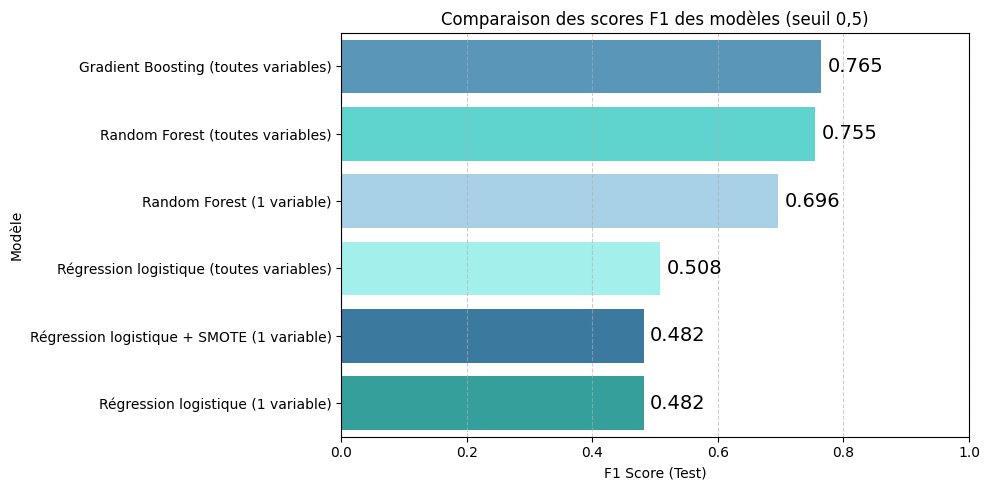

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x="F1", y="Modèle", data=comparaison, palette=pio.templates["jedha"].layout.colorway, hue="Modèle", legend=False)
plt.title("Comparaison des scores F1 des modèles (seuil 0,5)")
plt.xlabel("F1 Score (Test)")
plt.ylabel("Modèle")
plt.xlim(0, 1)
plt.grid(axis="x", linestyle="--", alpha=0.6)

for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.01, p.get_y() + p.get_height() / 2,
            f'{width:.3f}', va="center", fontsize=14)

plt.tight_layout()
plt.show()

Avec le seuil par défaut de 0,5, la progression semble logique : modèle linéaire < modèle non linéaire, 1 variable < toutes les variables.

Mais la colonne précision / recall montre deux comportements très différents : les régressions logistiques repèrent presque tous les abonnés mais font énormément de fausses alertes, alors que les modèles à base d'arbres sont plus prudents. La Partie 3 regarde si ce déséquilibre vient du modèle lui-même ou seulement du seuil.

#### Matrice de confusion pour le meilleur modèle (Gradient Boosting toutes variables)

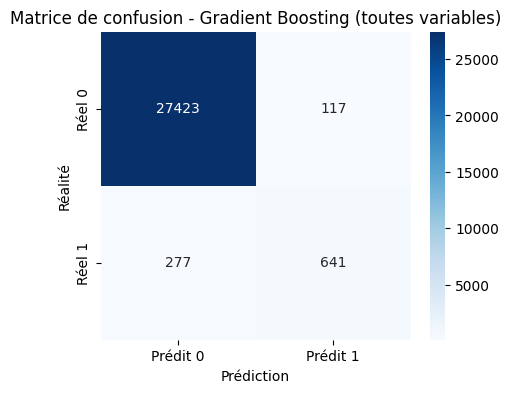

In [36]:
#Matrice de confusion

Y_pred_gb_allvars = gs_gb.predict(X_test_allvars_processed)
cm_gb_allvars = confusion_matrix(Y_test_encoded, Y_pred_gb_allvars)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_gb_allvars, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Prédit 0","Prédit 1"],
                yticklabels=["Réel 0","Réel 1"])
ax.set_ylabel("Réalité"); ax.set_xlabel("Prédiction")
plt.title("Matrice de confusion - Gradient Boosting (toutes variables)"); plt.show()

Sur les 918 abonnés du jeu de test, le Gradient Boosting en repère 641, avec 117 fausses alertes.

# Partie 3 — Précision, recall et choix du seuil de décision

Jusqu'ici, chaque modèle prédit « abonné » dès que sa probabilité dépasse 0,5. C'est le seuil par défaut, mais rien ne dit que c'est le bon quand les abonnés ne représentent que 3,2 % des visiteurs.

### Courbe ROC : les modèles savent-ils bien classer les visiteurs ?

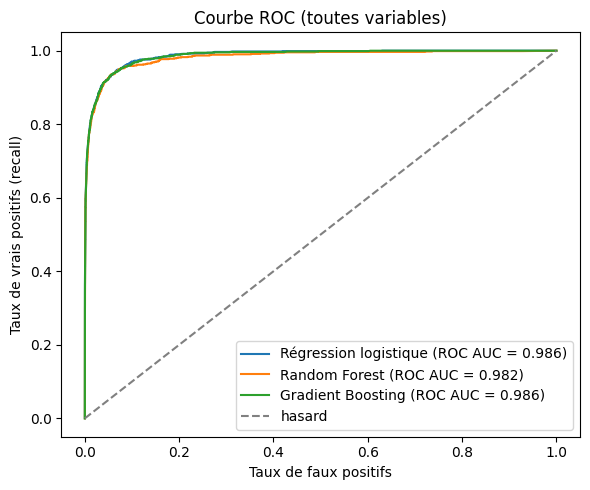

In [37]:
# La courbe ROC montre si le modèle donne des probabilités plus élevées aux abonnés qu'aux non-abonnés,
# indépendamment du seuil choisi. Plus l'aire sous la courbe (ROC AUC) est proche de 1, mieux c'est.
modeles_roc = {
    "Régression logistique": model_logreg_allvars,
    "Random Forest": gs_rf_allvars.best_estimator_,
    "Gradient Boosting": gs_gb.best_estimator_,
}
plt.figure(figsize=(6, 5))
for nom, modele in modeles_roc.items():
    proba = modele.predict_proba(X_test_allvars_processed)[:, 1]
    fpr, tpr, _ = roc_curve(Y_test_encoded, proba)
    plt.plot(fpr, tpr, label=f"{nom} (ROC AUC = {roc_auc_score(Y_test_encoded, proba):.3f})")
plt.plot([0, 1], [0, 1], ls="--", c="grey", label="hasard")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs (recall)")
plt.title("Courbe ROC (toutes variables)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

Les trois courbes sont presque superposées : la régression logistique (ROC AUC = 0.986) classe les visiteurs **aussi bien** que le Gradient Boosting (0.986), et un peu mieux que le Random Forest (0.982).

Autrement dit, la régression logistique sait très bien distinguer les abonnés des non-abonnés. Si son F1 est mauvais, c'est donc l'endroit où elle place la barre (le seuil) qui pose problème, pas le modèle.

### Recherche du meilleur seuil

Méthode : je mets de côté 20 % du jeu d'entraînement comme **jeu de validation**. Le modèle apprend sur les 80 % restants, puis je teste tous les seuils de 0,05 à 0,99 sur la validation et je garde celui qui donne le meilleur F1.

Le seuil est donc choisi sur des visiteurs que le modèle n'a pas vus pendant son apprentissage, et **sans toucher au jeu de test**, qui sert uniquement à vérifier le résultat final.

In [38]:
# 1. Jeu de validation : 20 % du train, avec la même proportion d'abonnés
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_allvars_processed, Y_train_encoded, test_size=0.2, random_state=0, stratify=Y_train_encoded
)

# 2. Fonction qui entraîne un modèle sur X_fit, puis cherche le seuil qui maximise le F1 sur la validation
def meilleur_seuil(modele, X_apprentissage, y_apprentissage, X_validation, y_validation):
    modele.fit(X_apprentissage, y_apprentissage)
    proba_val = modele.predict_proba(X_validation)[:, 1]
    seuils = np.arange(0.05, 1.00, 0.01)
    f1_par_seuil = [f1_score(y_validation, (proba_val >= s).astype(int)) for s in seuils]
    meilleur = round(float(seuils[int(np.argmax(f1_par_seuil))]), 2)
    return meilleur, seuils, f1_par_seuil

# 3. Seuil pour la régression logistique et pour le Gradient Boosting (mêmes réglages que plus haut)
seuil_lr, seuils, f1_lr = meilleur_seuil(
    LogisticRegression(random_state=0, class_weight="balanced"), X_fit, y_fit, X_val, y_val)
seuil_gb, seuils, f1_gb_seuils = meilleur_seuil(
    GradientBoostingClassifier(random_state=0, **gs_gb.best_params_), X_fit, y_fit, X_val, y_val)  # ** : reprend les meilleurs réglages du GridSearch

print("Seuil retenu — régression logistique :", seuil_lr)
print("Seuil retenu — Gradient Boosting     :", seuil_gb)

Seuil retenu — régression logistique : 0.95
Seuil retenu — Gradient Boosting     : 0.38


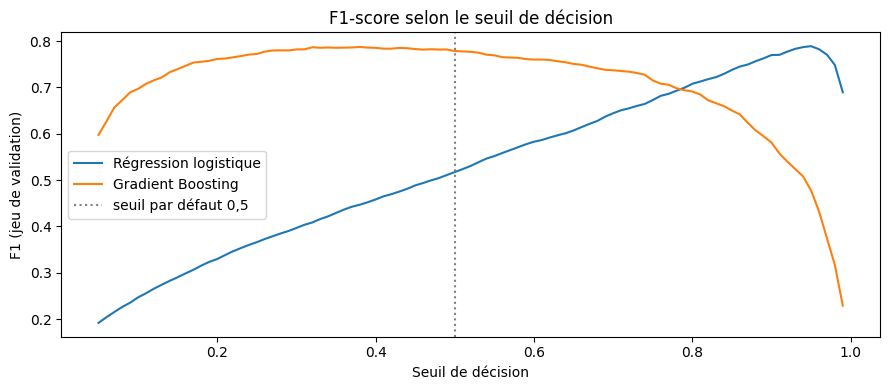

In [39]:
plt.figure(figsize=(9, 4))
plt.plot(seuils, f1_lr, label="Régression logistique")
plt.plot(seuils, f1_gb_seuils, label="Gradient Boosting")
plt.axvline(0.5, ls=":", c="grey", label="seuil par défaut 0,5")
plt.xlabel("Seuil de décision"); plt.ylabel("F1 (jeu de validation)")
plt.title("F1-score selon le seuil de décision")
plt.legend(); plt.tight_layout(); plt.show()

Les deux courbes sont très différentes :
- pour la **régression logistique**, le F1 augmente presque jusqu'au bout : le meilleur seuil est à **0,95**. C'est très élevé, parce que `class_weight="balanced"` gonfle toutes ses probabilités d'abonnement ;
- pour le **Gradient Boosting**, la courbe est plate entre 0,3 et 0,5 : le meilleur seuil est à **0,38**, mais le seuil par défaut n'en était pas loin.

In [40]:
# 4. Vérification sur le jeu de test, avec les modèles entraînés sur tout le train
proba_test_lr = model_logreg_allvars.predict_proba(X_test_allvars_processed)[:, 1]
proba_test_gb = gs_gb.best_estimator_.predict_proba(X_test_allvars_processed)[:, 1]

resultats = []   # nouveau tableau pour comparer seuil 0,5 et seuil choisi
afficher_scores("Régression logistique — seuil 0,5", Y_test_encoded, (proba_test_lr >= 0.5).astype(int))
afficher_scores(f"Régression logistique — seuil {seuil_lr}", Y_test_encoded, (proba_test_lr >= seuil_lr).astype(int))
afficher_scores("Gradient Boosting — seuil 0,5", Y_test_encoded, (proba_test_gb >= 0.5).astype(int))
afficher_scores(f"Gradient Boosting — seuil {seuil_gb}", Y_test_encoded, (proba_test_gb >= seuil_gb).astype(int))
display(pd.DataFrame(resultats))

Régression logistique — seuil 0,5 — F1 : 0.508 | précision : 0.349 | recall : 0.936
Régression logistique — seuil 0.95 — F1 : 0.767 | précision : 0.798 | recall : 0.737
Gradient Boosting — seuil 0,5 — F1 : 0.765 | précision : 0.846 | recall : 0.698
Gradient Boosting — seuil 0.38 — F1 : 0.768 | précision : 0.792 | recall : 0.745


,Modèle,F1,Précision,Recall
0,"Régression logistique — seuil 0,5",0.508,0.349,0.936
1,Régression logistique — seuil 0.95,0.767,0.798,0.737
2,"Gradient Boosting — seuil 0,5",0.765,0.846,0.698
3,Gradient Boosting — seuil 0.38,0.768,0.792,0.745


C'est le résultat le plus important du notebook : **le choix du seuil a plus d'effet que le choix du modèle.**

- La régression logistique passe de **0.508 à 0.767** de F1 sans changer de modèle, simplement avec un seuil adapté. Elle rattrape le Gradient Boosting.
- Pour le Gradient Boosting, le gain est minime (0.765 → 0.768) : il repère plus d'abonnés (recall 0.745 contre 0.698), au prix d'un peu plus de fausses alertes (précision 0.792 contre 0.846).

Une fois les seuils réglés, les deux modèles se valent.

### Modèle retenu : rapport complet et matrice de confusion

              precision    recall  f1-score   support

  non abonné      0.992     0.993     0.992     27540
      abonné      0.792     0.745     0.768       918

    accuracy                          0.985     28458
   macro avg      0.892     0.869     0.880     28458
weighted avg      0.985     0.985     0.985     28458



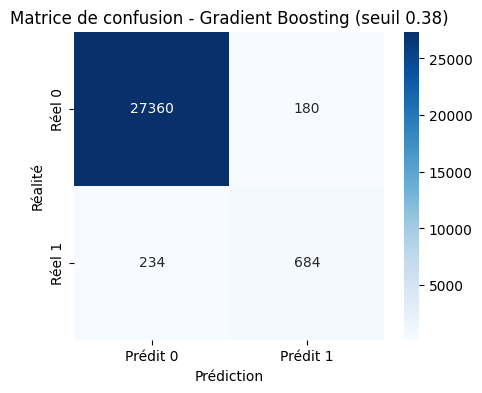

In [41]:
Y_pred_final = (proba_test_gb >= seuil_gb).astype(int)
print(classification_report(Y_test_encoded, Y_pred_final, target_names=["non abonné", "abonné"], digits=3))

cm = confusion_matrix(Y_test_encoded, Y_pred_final)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Prédit 0","Prédit 1"],
            yticklabels=["Réel 0","Réel 1"])
ax.set_ylabel("Réalité"); ax.set_xlabel("Prédiction")
plt.title(f"Matrice de confusion - Gradient Boosting (seuil {seuil_gb})"); plt.show()

**Modèle retenu : Gradient Boosting, seuil 0,38, F1 test = 0.768.**

Sur les 918 abonnés du jeu de test, il en repère **684** (recall 0.745) et en manque 234, avec **180** fausses alertes (précision 0.792). Par rapport au seuil de 0,5, il repère 43 abonnés de plus pour 63 fausses alertes supplémentaires.

Le choix est serré : la régression logistique avec son seuil ajusté fait presque aussi bien (0.767) et serait plus simple à expliquer. Je garde le Gradient Boosting parce que le challenge est noté au F1.

L'accuracy de 98,5 % ne dit presque rien ici : un modèle qui répondrait « personne ne s'abonne » ferait déjà 96,8 %.

# Partie 4 — Que reste-t-il sans le nombre de pages vues ?

Le nombre de pages vues est de loin la variable la plus utile au modèle. Mais c'est surtout un signe d'engagement : un visiteur déjà intéressé lit plus, et on ne connaît ce nombre qu'à la fin de la visite. L'équipe ne peut pas vraiment agir dessus.

Question : **sans cette variable, que peut-on encore dire à partir de ce qu'on sait dès l'arrivée du visiteur** (pays, âge, nouveau ou non, source) ?

In [42]:
# Même préprocessing que plus haut, mais sans total_pages_visited
numeric_features_sans = ["age", "new_user"]
categorical_features_sans = ["country", "source"]

preprocessor_sans = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features_sans),
    ("cat", Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features_sans)
])
X_train_sans = preprocessor_sans.fit_transform(train_df[numeric_features_sans + categorical_features_sans])
X_test_sans  = preprocessor_sans.transform(test_df[numeric_features_sans + categorical_features_sans])

# Même découpage train / validation que pour le seuil (même random_state : ce sont les mêmes visiteurs)
X_fit_sans, X_val_sans, y_fit_sans, y_val_sans = train_test_split(
    X_train_sans, Y_train_encoded, test_size=0.2, random_state=0, stratify=Y_train_encoded
)
seuil_sans, _, _ = meilleur_seuil(GradientBoostingClassifier(random_state=0), X_fit_sans, y_fit_sans, X_val_sans, y_val_sans)

# Modèle final entraîné sur tout le train, évalué sur le test
gb_sans = GradientBoostingClassifier(random_state=0).fit(X_train_sans, Y_train_encoded)
proba_sans = gb_sans.predict_proba(X_test_sans)[:, 1]

resultats = []
afficher_scores(f"Gradient Boosting sans pages vues — seuil {seuil_sans}", Y_test_encoded, (proba_sans >= seuil_sans).astype(int))
print("ROC AUC :", round(roc_auc_score(Y_test_encoded, proba_sans), 3))

Gradient Boosting sans pages vues — seuil 0.12 — F1 : 0.217 | précision : 0.162 | recall : 0.329
ROC AUC : 0.828


Sans le nombre de pages vues, le modèle ne sait plus dire qui va s'abonner : F1 de 0.217, et seulement 16 % de bonnes réponses quand il annonce un abonné.

En revanche, le ROC AUC reste de **0.828** : le modèle sait encore classer les visiteurs du moins prometteur au plus prometteur. C'est insuffisant pour cibler un visiteur précis, mais suffisant pour repérer des profils qui s'abonnent plus ou moins.

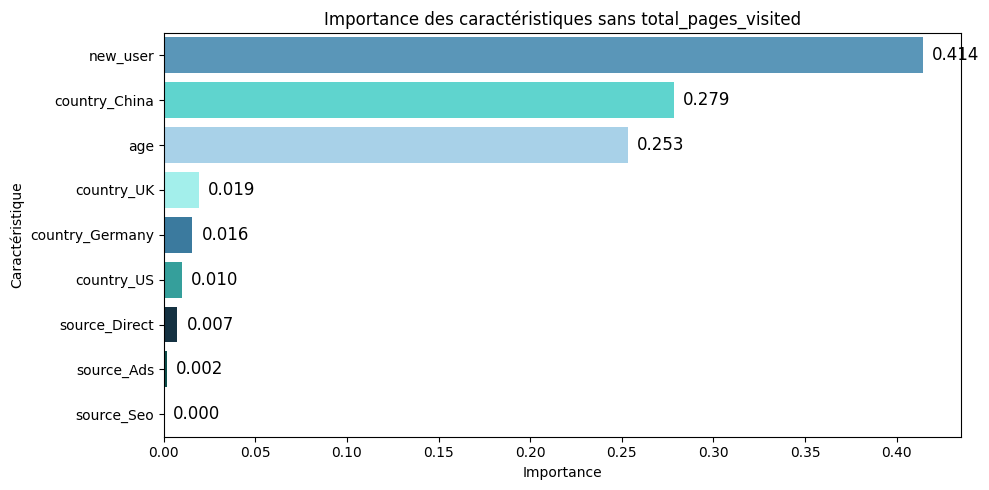

In [43]:
# Importance des variables sans le nombre de pages vues
col_names_sans = numeric_features_sans + list(
    preprocessor_sans.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features_sans))
feat_imp_sans = pd.DataFrame({
    "feature":    col_names_sans,
    "importance": gb_sans.feature_importances_
}).sort_values("importance", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x="importance", y="feature", data=feat_imp_sans, palette=pio.templates["jedha"].layout.colorway, hue="feature", legend=False, ax=ax)
for p in ax.patches:
    ax.text(p.get_width() + 0.005, p.get_y() + p.get_height() / 2, f'{p.get_width():.3f}', va='center', fontsize=12)
plt.title("Importance des caractéristiques sans total_pages_visited")
plt.xlabel("Importance"); plt.ylabel("Caractéristique")
plt.tight_layout(); plt.show()

Sans les pages vues, trois variables ressortent :
- `new_user` (0.41) : les visiteurs qui reviennent s'abonnent cinq fois plus que les nouveaux (7,2 % contre 1,4 % dans l'EDA) ;
- `country_China` (0.28) : la Chine convertit presque à zéro (0,13 %) ;
- `age` (0.25) : les visiteurs plus âgés s'abonnent un peu moins.

Les autres pays et la source pèsent très peu. Ce sont les leviers que l'équipe peut vraiment piloter, puisqu'elle connaît ces informations dès l'arrivée du visiteur.

# Partie 5 — Prédictions sur le jeu de test et soumission

### Import du fichier test

In [44]:
df_test = pd.read_csv(DATA_DIR / "conversion_data_test.csv")
print(f"Test set : {df_test.shape[0]} lignes, {df_test.shape[1]} colonnes")

Test set : 31620 lignes, 5 colonnes


### Préprocessing et prédiction

In [45]:
# On applique le MÊME preprocessor que pour l'entraînement
X_new_processed = preprocessor_allvars.transform(df_test)

# Prédiction avec le modèle retenu (Gradient Boosting) et le seuil choisi en Partie 3
proba_new = gs_gb.best_estimator_.predict_proba(X_new_processed)[:, 1]
predictions = (proba_new >= seuil_gb).astype(int)

Étape volontairement courte : c'est exactement le même pipeline (preprocessing + modèle) que celui validé en Partie 3, avec son seuil, appliqué cette fois sur des données inconnues par le modèle.

Aucune fuite d'information possible puisque `preprocessor_allvars` n'a été fit que sur `conversion_data_train.csv`.

### Construction et export du fichier de soumission

In [46]:
# Création du fichier au format attendu par le classement : une seule colonne "converted"

submission = pd.DataFrame({
    "converted": predictions
})
print(submission.head())
print(f"Distribution des prédictions :\n{submission['converted'].value_counts()}")

# Export en local, prêt à être envoyé pour évaluation du F1 sur le vrai jeu de test

submission.to_csv("conversion_data_test_predictions.csv", index=False)
print("✓ Fichier de soumission généré")

   converted
0          1
1          0
2          0
3          0
4          0
Distribution des prédictions :
converted
0    30684
1      936
Name: count, dtype: int64
✓ Fichier de soumission généré


**936 abonnements prédits sur 31 620 lignes, soit 3,0 %** : très proche du taux de 3,2 % observé sur le train.

Cette proximité sert de garde-fou : un résultat du type « 0 conversion prédite » ou « 50 % de conversions prédites » aurait signalé un bug avant la soumission.

# Partie 6 — Recommandations pour améliorer le taux de conversion

In [47]:
# Importance des variables dans le modèle retenu (Gradient Boosting)
feat_imp_gb = pd.DataFrame({
    "feature":    col_names_allvars,
    "importance": gs_gb.best_estimator_.feature_importances_
}).sort_values("importance", ascending=False)
feat_imp_gb["importance_%"] = (feat_imp_gb["importance"] * 100).round(1)
feat_imp_gb

,feature,importance,importance_%
2,total_pages_visited,0.897512,89.8
1,new_user,0.043784,4.4
3,country_China,0.040257,4.0
0,age,0.016695,1.7
6,country_US,0.000572,0.1
5,country_UK,0.000475,0.0
4,country_Germany,0.000314,0.0
8,source_Direct,0.000271,0.0
9,source_Seo,0.000075,0.0
7,source_Ads,0.000045,0.0


Le Gradient Boosting retenu (seuil 0,38, F1 = 0.768) fait ressortir un déséquilibre net entre les variables : `total_pages_visited` représente à elle seule **90 %** de l'importance, contre 10 % pour toutes les autres réunies (surtout `new_user` et `country_China`).

**Attention à la lecture de ce chiffre :** le nombre de pages vues prédit très bien l'abonnement, mais ça ne veut pas dire que faire lire plus de pages fera s'abonner plus de visiteurs. Un visiteur déjà intéressé lit forcément plus. C'est un **indicateur d'engagement**, pas une cause démontrée.

### Recommandation 1 — Suivre l'engagement, et tester avant d'investir

- Suivre le nombre de pages vues par visite comme indicateur d'engagement.
- Avant d'investir dans le parcours de lecture (articles liés, « à lire aussi », liens internes), le **tester par un A/B test** : un groupe avec le parcours enrichi, un groupe sans, et comparer le taux d'abonnement.

### Recommandation 2 — Agir sur ce que l'on sait dès l'arrivée du visiteur (Partie 4)

- **Chine** : un quart du trafic pour 0,13 % d'abonnés. Avant toute action, comprendre pourquoi : langue du site, accès, pertinence du contenu.
- **Nouveaux visiteurs** : 68,5 % du trafic, mais cinq fois moins d'abonnements que les visiteurs qui reviennent. Travailler le retour du visiteur (contenus à suivre, rappel) plutôt que l'abonnement immédiat.
- **Allemagne et Royaume-Uni** : les pays qui convertissent le mieux, mais qui pèsent peu dans le trafic. Piste pour de l'acquisition ciblée.
- **Source d'arrivée** : effet faible. Elle ne justifie pas à elle seule de revoir la répartition du budget marketing.

### Limites

- Ce sont des associations, pas des causes : chaque piste est à valider par un test.
- Les modèles ont été évalués sur un seul découpage des données, et les écarts entre les meilleurs (0.765 à 0.768) sont trop faibles pour les départager.
- Le préprocessing est appliqué avant les GridSearch. En bonne pratique, il faudrait l'intégrer avec le modèle dans une même `Pipeline`, pour qu'il soit recalculé à chaque fold de la validation croisée.
- Pistes non explorées : `class_weight` sur le Random Forest, une recherche d'hyperparamètres plus large (`RandomizedSearchCV`).
- Avec seulement 5 variables, le score plafonne autour de 0.77.